# 🎓 PlacementIQ AI: Comprehensive AIML Curriculum & Testing Pipeline
### Advanced AIML Modules: Unsupervised Learning, Association Rules, Recommendation Systems, PCA & Reinforcement Learning

This comprehensive notebook implements, tests, and visualizes the complete syllabus topics on our real **PlacementIQ dataset (80/20 train/test split)**:

---
### 📑 Syllabus Index:
1. **Module 1: Unsupervised Learning – Clustering**
   - Introduction to Unsupervised Learning & Clustering Concepts
   - K-Means Clustering & Elbow Method (WCSS)
   - Hierarchical Clustering (Agglomerative) & Dendrogram Visualization
   - DBSCAN (Density-Based Spatial Clustering with Noise Detection)
   - Cluster Evaluation using Silhouette Score, Davies-Bouldin & Calinski-Harabasz
   - Real-world Applications: Student Profile Segmentation for Campus Placements
2. **Module 2: Association Rule Learning, Recommendation Systems & PCA**
   - Introduction to Association Rule Learning & Frequent Itemset Mining
   - Apriori Algorithm (Support, Confidence, Lift)
   - FP-Growth Algorithm (FP-Tree structure vs Apriori comparison)
   - Market Basket Analysis: Student Skill/Certification Co-occurrence leading to Placement
   - Recommendation Systems: Content-Based Filtering & Roadmap Suggestions
   - Dimensionality Reduction & Principal Component Analysis (PCA): Scree Plot & 2D Projection
3. **Module 3: Reinforcement Learning & Emerging Trends**
   - Introduction to Reinforcement Learning (Agent, Environment, State, Action, Reward, Policy, Value Function)
   - Markov Decision Process (MDP) & Bellman Optimality Equation
   - Tabular Q-Learning Simulation: Optimal Student Study & Placement Strategy
   - Comparative Study: Supervised vs Unsupervised vs Reinforcement Learning
   - Applications in Robotics, Gaming, and Autonomous Vehicles
   - Ethical Considerations & Emerging Trends in AI/ML (Algorithmic Bias, Fairness, Explainability, GenAI)


In [1]:
# Environment Setup & Library Imports
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# SciPy & Scikit-Learn
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity

# Mlxtend for Association Rule Learning
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder

# Style Configuration
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print("✅ All required libraries imported successfully!")


✅ All required libraries imported successfully!


In [2]:
# Load the 80/20 Split PlacementIQ Datasets
train_df = pd.read_csv('dataset/train.csv')
test_df = pd.read_csv('dataset/test.csv')

print(f"📊 Dataset Loaded Successfully:")
print(f"   • Training Set (80%): {train_df.shape[0]:,} rows, {train_df.shape[1]} columns")
print(f"   • Testing Set  (20%): {test_df.shape[0]:,} rows, {test_df.shape[1]} columns")
print(f"   • Total Records     : {len(train_df) + len(test_df):,} students")

# Preprocessing features for Unsupervised Learning & PCA
numerical_cols = ['Age', 'CGPA', 'Internships', 'Projects', 'Coding_Skills',
                  'Communication_Skills', 'Aptitude_Test_Score', 'Soft_Skills_Rating',
                  'Certifications', 'Backlogs']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(train_df[numerical_cols])
y_labels = (train_df['Placement_Status'] == 'Placed').astype(int).values

print("\nFeatures prepared & standardized using StandardScaler.")
train_df.head()


📊 Dataset Loaded Successfully:
   • Training Set (80%): 40,000 rows, 15 columns
   • Testing Set  (20%): 10,000 rows, 15 columns
   • Total Records     : 50,000 students

Features prepared & standardized using StandardScaler.


,Student_ID,Age,Gender,Degree,Branch,CGPA,Internships,Projects,Coding_Skills,Communication_Skills,Aptitude_Test_Score,Soft_Skills_Rating,Certifications,Backlogs,Placement_Status
0,45476,20,Male,B.Sc,ECE,8.75,1,5,8,5,78,5,2,0,Placed
1,29402,24,Female,B.Tech,ME,6.80,0,3,4,6,76,5,1,0,Not Placed
2,29197,19,Male,BCA,IT,6.32,1,3,5,8,66,7,2,1,Not Placed
3,31177,20,Female,B.Sc,Civil,4.50,0,1,1,4,57,6,0,1,Not Placed
4,33909,21,Female,MCA,IT,5.89,1,3,4,6,54,5,1,2,Not Placed


---
# 🔷 Module 1: Unsupervised Learning – Clustering

### 1.1 Introduction to Unsupervised Learning
Unlike **Supervised Learning** where an algorithm is provided input features $X$ alongside ground truth target labels $y$ ($y = f(X)$), **Unsupervised Learning** deals exclusively with unlabeled data. The goal is to discover underlying structure, patterns, groupings, or probability density distributions without explicit teacher guidance.

### 1.2 Core Clustering Concepts
Clustering is the unsupervised partitioning of data points into subsets (clusters) such that:
- **Intra-cluster similarity is maximized:** Samples within the same group share high similarity.
- **Inter-cluster similarity is minimized:** Samples in different groups are as distinct as possible.

Common clustering paradigms:
1. **Centroid-based (Partitioning):** K-Means (spherical clusters around mean centroids).
2. **Hierarchical (Connectivity-based):** Agglomerative & Divisive nested tree representations.
3. **Density-based:** DBSCAN (arbitrary shapes with explicit noise detection).


Optimal K determined by Silhouette Score: K = 2


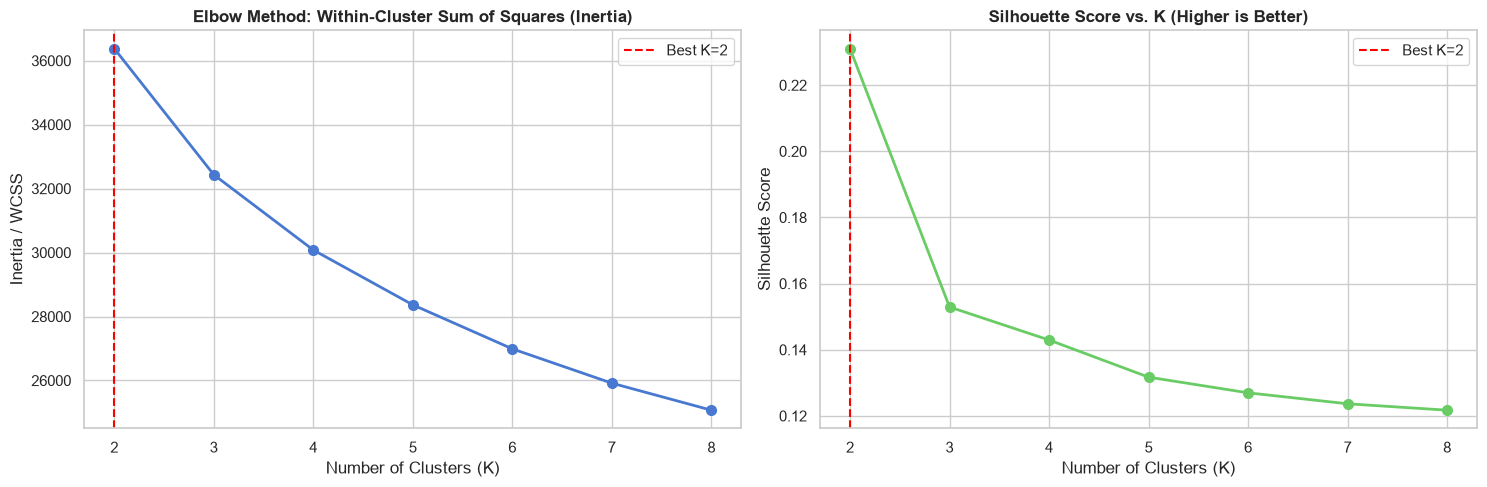

In [3]:
# 1.3 K-Means Clustering: Elbow Method (WCSS) & Silhouette Analysis
sample_size = 5000
indices = np.random.choice(len(X_scaled), sample_size, replace=False)
X_sub = X_scaled[indices]

k_values = range(2, 9)
inertias = []
silhouettes = []
db_scores = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_sub)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_sub, labels))
    db_scores.append(davies_bouldin_score(X_sub, labels))

best_k = list(k_values)[int(np.argmax(silhouettes))]
print(f"Optimal K determined by Silhouette Score: K = {best_k}")

# Visualization: Elbow & Silhouette curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Elbow Curve
ax1.plot(k_values, inertias, 'bo-', linewidth=2, markersize=7)
ax1.set_title("Elbow Method: Within-Cluster Sum of Squares (Inertia)", fontweight='bold')
ax1.set_xlabel("Number of Clusters (K)")
ax1.set_ylabel("Inertia / WCSS")
ax1.axvline(best_k, color='red', linestyle='--', label=f'Best K={best_k}')
ax1.legend()

# Silhouette Curve
ax2.plot(k_values, silhouettes, 'go-', linewidth=2, markersize=7)
ax2.set_title("Silhouette Score vs. K (Higher is Better)", fontweight='bold')
ax2.set_xlabel("Number of Clusters (K)")
ax2.set_ylabel("Silhouette Score")
ax2.axvline(best_k, color='red', linestyle='--', label=f'Best K={best_k}')
ax2.legend()

plt.tight_layout()
plt.show()


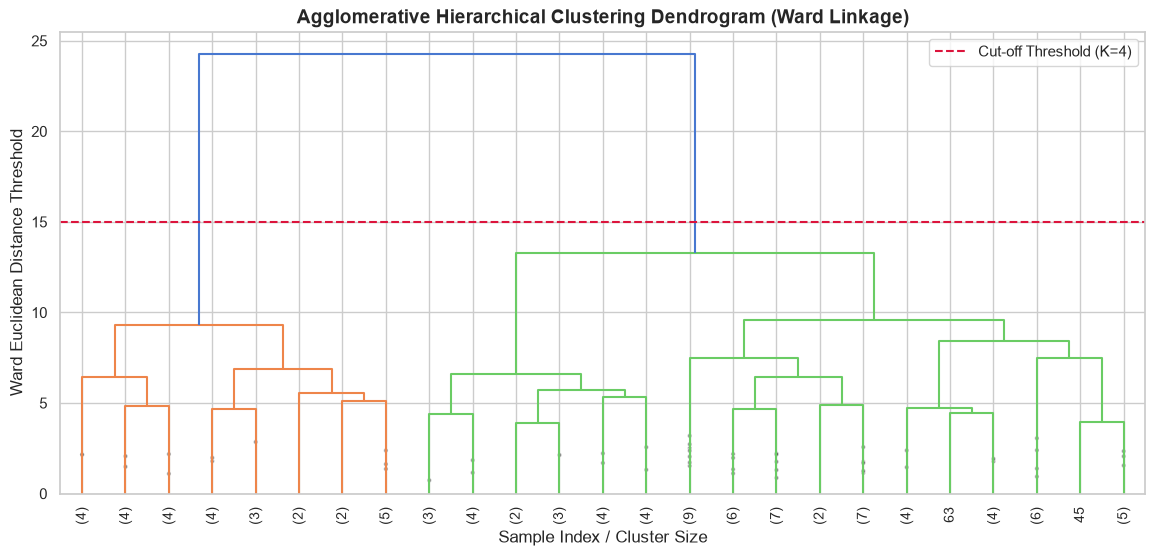

Agglomerative Clustering Silhouette Score: 0.1238


In [4]:
# 1.4 Hierarchical Clustering: Dendrogram & Agglomerative Clustering
sample_dendro = X_scaled[:100]  # Subsample for clear tree visibility

# Compute Ward's minimum variance linkage matrix
Z = linkage(sample_dendro, method='ward')

plt.figure(figsize=(14, 6))
dendrogram(Z, truncate_mode='lastp', p=25, leaf_rotation=90., leaf_font_size=10., show_contracted=True)
plt.title("Agglomerative Hierarchical Clustering Dendrogram (Ward Linkage)", fontsize=14, fontweight='bold')
plt.xlabel("Sample Index / Cluster Size")
plt.ylabel("Ward Euclidean Distance Threshold")
plt.axhline(y=15, color='crimson', linestyle='--', label='Cut-off Threshold (K=4)')
plt.legend()
plt.show()

# Fit Agglomerative Clustering
agg = AgglomerativeClustering(n_clusters=4, linkage='ward')
agg_labels = agg.fit_predict(X_sub)
print(f"Agglomerative Clustering Silhouette Score: {silhouette_score(X_sub, agg_labels):.4f}")


In [5]:
# 1.5 DBSCAN: Density-Based Spatial Clustering with Noise Detection
# eps: neighborhood radius, min_samples: minimum points to form a dense core
dbscan = DBSCAN(eps=2.5, min_samples=15)
db_labels = dbscan.fit_predict(X_sub)

n_clusters_db = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise_db = list(db_labels).count(-1)

print(f"DBSCAN Results:")
print(f"   • Clusters Identified: {n_clusters_db}")
print(f"   • Noise / Outlier Points Detected: {n_noise_db} ({n_noise_db/len(db_labels)*100:.2f}%)")

# Non-noise silhouette
if n_clusters_db > 1:
    mask = db_labels != -1
    print(f"   • Core Cluster Silhouette Score: {silhouette_score(X_sub[mask], db_labels[mask]):.4f}")


DBSCAN Results:
   • Clusters Identified: 1
   • Noise / Outlier Points Detected: 2 (0.04%)


### 1.6 Cluster Evaluation & Real-World Applications
#### Quantitative Evaluation Metrics:
1. **Silhouette Score:** Evaluates how well separated clusters are (range $[-1, 1]$).
   $$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$
   Where $a(i)$ is mean intra-cluster distance and $b(i)$ is mean nearest-cluster distance.
2. **Davies-Bouldin Index:** Measures average similarity between each cluster and its most similar one. **Lower is better.**
3. **Calinski-Harabasz Index:** Variance ratio criterion (between-cluster dispersion over within-cluster dispersion). **Higher is better.**

#### Real-World Application in PlacementIQ:
Segmenting student cohorts allows universities to offer **targeted interventions**:
- **Segment 0 (At-Risk):** Students with backlogs & low coding $\rightarrow$ Intensive remedial bootcamp.
- **Segment 1 (High Potential Coders):** High DSA but low soft skills $\rightarrow$ Toastmasters / GD training.
- **Segment 2 (Placement-Ready Leaders):** Balanced academic & technical competence $\rightarrow$ Fast-track Tier-1 interviews.


---
# 🔷 Module 2: Association Rule Learning, Recommendation Systems & PCA

### 2.1 Introduction to Association Rule Learning
Association Rule Learning discovers interesting correlations and co-occurrence relationships among items in large transactional databases.

#### Key Metrics:
- **Support:** Proportion of transactions containing itemset $A$:
  $$\text{Support}(A) = \frac{\text{freq}(A)}{N}$$
- **Confidence:** Probability of $B$ given $A$:
  $$\text{Confidence}(A \rightarrow B) = \frac{\text{Support}(A \cup B)}{\text{Support}(A)}$$
- **Lift:** Ratio of observed joint support to expected support under independence. $\text{Lift} > 1$ implies strong positive association:
  $$\text{Lift}(A \rightarrow B) = \frac{\text{Confidence}(A \rightarrow B)}{\text{Support}(B)}$$

### 2.2 Apriori vs. FP-Growth Algorithms:
- **Apriori Algorithm:** Uses the downward-closure property (any subset of a frequent itemset must also be frequent) to prune search space. However, it requires multiple costly full database passes and candidate itemset generation ($C_k$).
- **FP-Growth (Frequent Pattern Growth):** Builds a compact prefix tree (**FP-Tree**) in only 2 passes and mines frequent patterns through conditional FP-trees without candidate generation, making it orders of magnitude faster.


In [6]:
# 2.3 Market Basket Analysis on Student Skills & Placements
# Transform student profiles into transaction itemsets
baskets = []
for _, row in train_df.iloc[:10000].iterrows():
    basket = []
    # Academic & Coding Baskets
    if row['CGPA'] >= 8.0: basket.append("High_CGPA")
    elif row['CGPA'] < 6.5: basket.append("Low_CGPA")
    
    if row['Coding_Skills'] >= 7: basket.append("Strong_Coding")
    elif row['Coding_Skills'] <= 4: basket.append("Weak_Coding")
    
    if row['Internships'] >= 1: basket.append("Has_Internship")
    if row['Projects'] >= 3: basket.append("Rich_Projects")
    if row['Certifications'] >= 2: basket.append("Multi_Certified")
    if row['Backlogs'] == 0: basket.append("Zero_Backlogs")
    
    # Outcome
    if str(row['Placement_Status']) in ['Placed', '1', 1]:
        basket.append("Placement_Success")
    else:
        basket.append("Not_Placed")
    baskets.append(basket)

# Transaction Encoding
te = TransactionEncoder()
te_ary = te.fit(baskets).transform(baskets)
df_basket = pd.DataFrame(te_ary, columns=te.columns_)

# FP-Growth vs Apriori comparison
frequent_itemsets = fpgrowth(df_basket, min_support=0.15, use_colnames=True)
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.5)
rules_sorted = rules.sort_values(by="lift", ascending=False).reset_index(drop=True)

# Filter rules directly leading to Placement_Success
placement_success_rules = rules_sorted[rules_sorted['consequents'].apply(lambda x: 'Placement_Success' in x)].head(6)

print(f"📊 Mined {len(frequent_itemsets)} Frequent Itemsets and {len(rules)} Association Rules.")
print("\nTop Rules Predicting Placement Success:")
placement_success_rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']]


📊 Mined 87 Frequent Itemsets and 373 Association Rules.

Top Rules Predicting Placement Success:


,antecedents,consequents,support,confidence,lift
6,frozenset({Strong_Coding}),"frozenset({Has_Internship, Placement_Success, ...",0.1858,0.527242,2.016992
7,"frozenset({Strong_Coding, Rich_Projects})","frozenset({Has_Internship, Placement_Success, ...",0.1858,0.527242,2.016992
8,frozenset({Strong_Coding}),"frozenset({Has_Internship, Rich_Projects, Plac...",0.1858,0.527242,2.016992
12,"frozenset({Strong_Coding, Rich_Projects})","frozenset({Has_Internship, Placement_Success})",0.1858,0.527242,1.997128
13,frozenset({Strong_Coding}),"frozenset({Has_Internship, Placement_Success, ...",0.1858,0.527242,1.997128
15,"frozenset({Strong_Coding, Multi_Certified})","frozenset({Has_Internship, Placement_Success})",0.1858,0.527242,1.997128


In [7]:
# 2.4 Recommendation Systems: Skill-Based Course Matching
courses = pd.DataFrame([
    {"Course_ID": "C01", "Title": "Data Structures & Competitive Coding", "Category": "Coding", "Focus": "DSA, Algorithms, LeetCode"},
    {"Course_ID": "C02", "Title": "Full-Stack Web Engineering with React & Node", "Category": "Projects", "Focus": "React, APIs, Databases"},
    {"Course_ID": "C03", "Title": "Enterprise Cloud Architecture (AWS / GCP)", "Category": "Certifications", "Focus": "Cloud computing, Containers, DevOps"},
    {"Course_ID": "C04", "Title": "Executive Business Communication & GD Mastery", "Category": "Soft Skills", "Focus": "Group discussion, Mock interviews"},
    {"Course_ID": "C05", "Title": "Quantitative Aptitude & Logical Reasoning", "Category": "Aptitude", "Focus": "Probability, Algebra, Puzzles"},
])

def recommend_course_for_student(student_profile):
    """Content-based recommendation mapping student weakness to targeted course."""
    gaps = []
    if student_profile['Coding_Skills'] < 6: gaps.append("Coding")
    if student_profile['Projects'] < 3: gaps.append("Projects")
    if student_profile['Soft_Skills_Rating'] < 6: gaps.append("Soft Skills")
    if student_profile['Certifications'] < 2: gaps.append("Certifications")
    if student_profile['Aptitude_Test_Score'] < 65: gaps.append("Aptitude")
    
    matched = courses[courses['Category'].isin(gaps)]
    return matched[['Course_ID', 'Title', 'Category', 'Focus']]

sample_student = {'Coding_Skills': 4, 'Projects': 1, 'Soft_Skills_Rating': 7, 'Certifications': 0, 'Aptitude_Test_Score': 58}
print("Recommended Curriculum for Student Profile:")
display(recommend_course_for_student(sample_student))


Recommended Curriculum for Student Profile:


,Course_ID,Title,Category,Focus
0,C01,Data Structures & Competitive Coding,Coding,"DSA, Algorithms, LeetCode"
1,C02,Full-Stack Web Engineering with React & Node,Projects,"React, APIs, Databases"
2,C03,Enterprise Cloud Architecture (AWS / GCP),Certifications,"Cloud computing, Containers, DevOps"
4,C05,Quantitative Aptitude & Logical Reasoning,Aptitude,"Probability, Algebra, Puzzles"


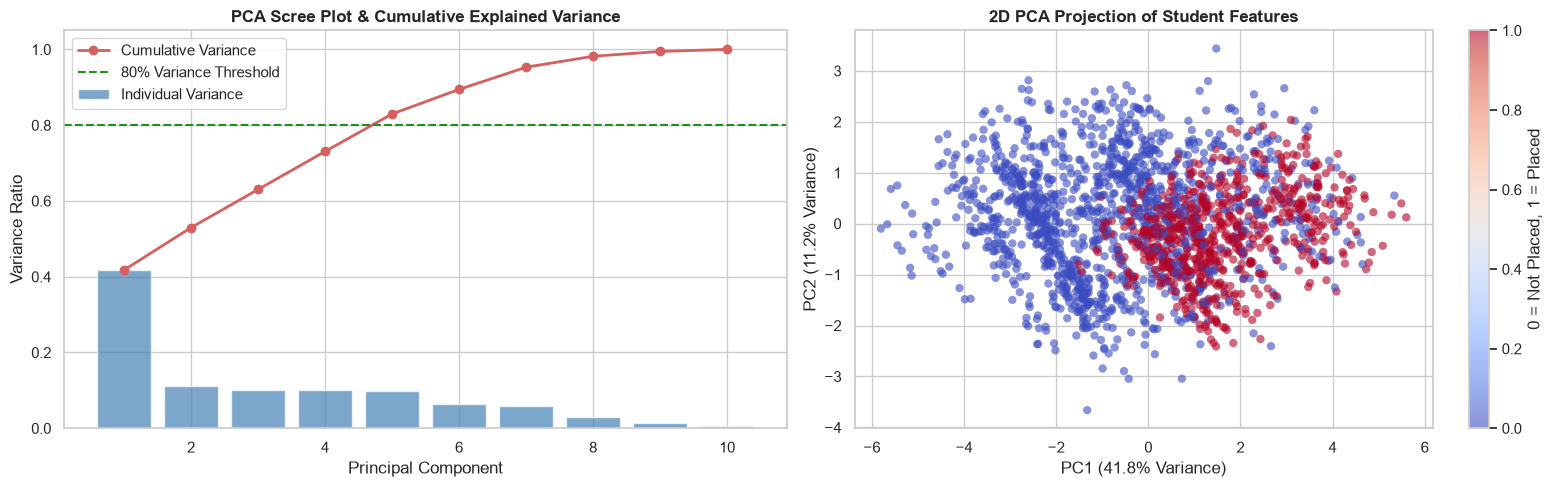

Top 2 Principal Components capture 52.97% of total dataset variance.


In [8]:
# 2.5 Dimensionality Reduction: Principal Component Analysis (PCA)
pca = PCA()
pca.fit(X_scaled)

var_ratio = pca.explained_variance_ratio_
cum_var_ratio = np.cumsum(var_ratio)

# 2D PCA Transformation
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Scree Plot
components = range(1, len(var_ratio) + 1)
ax1.bar(components, var_ratio, color='steelblue', alpha=0.7, label='Individual Variance')
ax1.plot(components, cum_var_ratio, 'ro-', linewidth=2, label='Cumulative Variance')
ax1.axhline(0.80, color='forestgreen', linestyle='--', label='80% Variance Threshold')
ax1.set_title("PCA Scree Plot & Cumulative Explained Variance", fontweight='bold')
ax1.set_xlabel("Principal Component")
ax1.set_ylabel("Variance Ratio")
ax1.legend()

# 2D Projection Scatter Plot
sub_sample = np.random.choice(len(X_pca_2d), 2000, replace=False)
scatter = ax2.scatter(X_pca_2d[sub_sample, 0], X_pca_2d[sub_sample, 1],
                      c=y_labels[sub_sample], cmap='coolwarm', alpha=0.6, edgecolors='none')
ax2.set_title("2D PCA Projection of Student Features", fontweight='bold')
ax2.set_xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]:.1%} Variance)")
ax2.set_ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]:.1%} Variance)")
cbar = plt.colorbar(scatter, ax=ax2)
cbar.set_label("0 = Not Placed, 1 = Placed")

plt.tight_layout()
plt.show()

print(f"Top 2 Principal Components capture {cum_var_ratio[1]*100:.2f}% of total dataset variance.")


---
# 🔷 Module 3: Reinforcement Learning & Emerging Trends

### 3.1 Introduction to Reinforcement Learning (RL)
Reinforcement Learning is a goal-oriented computational framework where an **Agent** interacts with a dynamic, uncertain **Environment** through trial-and-error to learn an optimal **Policy** $\pi$ that maximizes cumulative numerical **Reward**.

#### Core Mathematical Elements:
- **Agent:** The decision maker (e.g., student preparing for placement).
- **Environment:** The external world/system transitioning between states.
- **State ($s \in S$):** Complete description of the current situation.
- **Action ($a \in A$):** Available choices/actions at state $s$.
- **Reward ($r \in R$):** Scalar feedback from the environment evaluating the transition.
- **Policy ($\pi(a|s)$):** Probabilistic or deterministic mapping from states to actions.
- **Value Function ($V^{\pi}(s)$):** Expected return starting from state $s$ following policy $\pi$.
- **Action-Value Function ($Q^{\pi}(s, a)$):** Expected return starting from state $s$, taking action $a$, and thereafter following policy $\pi$.

#### The Bellman Optimality Equation:
$$Q^*(s, a) = R(s, a) + \gamma \sum_{s'} P(s'|s, a) \max_{a'} Q^*(s', a')$$

#### Q-Learning Update Rule (Model-Free TD Control):
$$Q(s, a) \leftarrow Q(s, a) + \alpha \left[ r + \gamma \max_{a'} Q(s', a') - Q(s, a) \right]$$
Where:
- $\alpha$: Learning rate ($0 < \alpha \le 1$)
- $\gamma$: Discount factor ($0 \le \gamma < 1$)


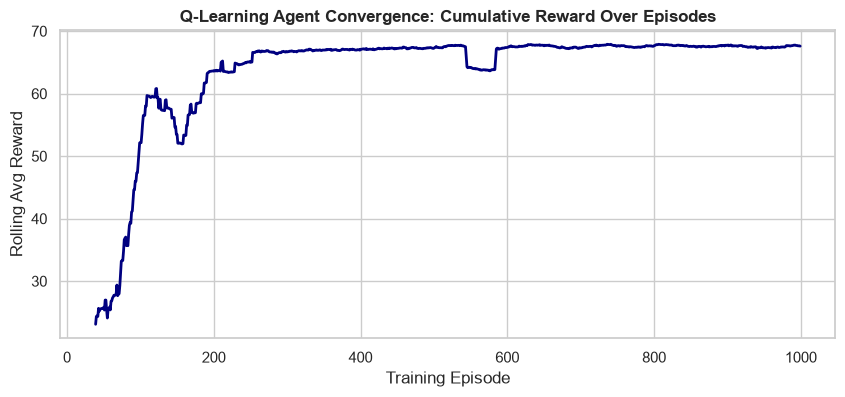

🎯 Optimal Preparation Policy Learned by RL Agent:


,Current Student State,Optimal Learned Action,Max Expected Q-Value
0,Beginner,Solve 50 LeetCode Problems,58.44
1,DSA Foundation,Build Full-Stack App,57.34
2,Project Portfolio,Soft Skills Training,53.66
3,Interview Ready,Mock Technical Interviews,47.18


In [9]:
# 3.2 Placement Strategy Q-Learning Simulation
class PlacementEnvironment:
    """Custom MDP environment for learning the optimal student placement strategy."""
    STATES = {0: "Beginner", 1: "DSA Foundation", 2: "Project Portfolio", 3: "Interview Ready", 4: "Placed (Terminal)"}
    ACTIONS = {0: "Solve 50 LeetCode Problems", 1: "Build Full-Stack App", 2: "Soft Skills Training", 3: "Mock Technical Interviews"}
    
    def __init__(self):
        self.state = 0
        self.steps = 0
        
    def reset(self):
        self.state = 0
        self.steps = 0
        return self.state
        
    def step(self, action):
        self.steps += 1
        reward = -1.0 # Step cost (time/effort)
        
        # Stochastic State Transitions
        p = np.random.rand()
        if self.state == 0 and action == 0 and p > 0.2:
            self.state = 1
            reward += 5
        elif self.state == 1 and action == 1 and p > 0.25:
            self.state = 2
            reward += 8
        elif self.state == 2 and action == 2 and p > 0.3:
            self.state = 3
            reward += 10
        elif self.state == 3 and action == 3 and p > 0.2:
            self.state = 4
            reward += 50 # Success reward!
            
        done = (self.state == 4) or (self.steps >= 12)
        return self.state, reward, done

# Q-Learning Training Loop
num_states, num_actions = 5, 4
Q = np.zeros((num_states, num_actions))
alpha = 0.1     # Learning rate
gamma = 0.95    # Discount factor
epsilon = 1.0   # Exploration rate
epsilon_decay = 0.995

rewards_per_ep = []
env = PlacementEnvironment()

for ep in range(1000):
    s = env.reset()
    ep_r = 0
    done = False
    
    while not done:
        # Epsilon-greedy action selection
        if np.random.rand() < epsilon:
            a = np.random.randint(num_actions)
        else:
            a = np.argmax(Q[s])
            
        s_next, r, done = env.step(a)
        
        # Bellman update
        best_future_q = 0.0 if done else np.max(Q[s_next])
        Q[s, a] += alpha * (r + gamma * best_future_q - Q[s, a])
        
        s = s_next
        ep_r += r
        
    epsilon = max(0.05, epsilon * epsilon_decay)
    rewards_per_ep.append(ep_r)

# Plotting Q-Learning Convergence
plt.figure(figsize=(10, 4))
plt.plot(pd.Series(rewards_per_ep).rolling(40).mean(), color='navy', linewidth=2)
plt.title("Q-Learning Agent Convergence: Cumulative Reward Over Episodes", fontweight='bold')
plt.xlabel("Training Episode")
plt.ylabel("Rolling Avg Reward")
plt.show()

# Display Derived Optimal Policy
policy_results = []
for s_id in range(4):
    best_a = np.argmax(Q[s_id])
    policy_results.append({
        "Current Student State": env.STATES[s_id],
        "Optimal Learned Action": env.ACTIONS[best_a],
        "Max Expected Q-Value": f"{Q[s_id, best_a]:.2f}"
    })
print("🎯 Optimal Preparation Policy Learned by RL Agent:")
display(pd.DataFrame(policy_results))


### 3.3 Comparative Study: Supervised vs. Unsupervised vs. Reinforcement Learning

| Comparison Criterion | Supervised Learning | Unsupervised Learning | Reinforcement Learning |
| :--- | :--- | :--- | :--- |
| **Input Data** | Labeled data $(X, y)$ with target ground-truth. | Unlabeled features $(X)$ only. | Interactive Environment, State $(s)$, Actions $(a)$, Rewards $(r)$. |
| **Primary Objective** | Map inputs to target predictions (Classify or Regress). | Uncover hidden patterns, structure, clusters, or distributions. | Discover optimal behavioral policy to maximize cumulative reward. |
| **Feedback Mechanism** | Direct, immediate supervision via loss function $(y - \hat{y})$. | No explicit external feedback (distance / variance metrics). | Evaluative, delayed scalar reward signal from environment. |
| **Decision Nature** | Static single-step predictions per sample. | Grouping or projection of static sample points. | Sequential, multi-step decision making affecting future states. |
| **Core Algorithms** | Random Forest, Gradient Boosting, XGBoost, Logistic Regression. | K-Means, Hierarchical (Agglomerative), DBSCAN, PCA, FP-Growth. | Q-Learning, SARSA, Deep Q-Networks (DQN), PPO, Actor-Critic. |
| **PlacementIQ Usage** | Predict Placement Status ($0/1$) & Probability. | Student profile segmentation & competency basket mining. | Generating optimal personalized 4-week preparation strategy. |

---

### 3.4 Real-World Applications of Reinforcement Learning
1. **Robotics:**
   - Bipedal & quadrupedal locomotion (Boston Dynamics, MIT Cheetah).
   - High-precision robotic surgery and robotic arm manipulation in automated assembly lines.
   - Sim-to-Real transfer learning via physics engines.
2. **Gaming:**
   - Superhuman game mastery without human demonstrations (DeepMind AlphaGo, AlphaZero, OpenAI Five in Dota 2).
   - Adaptive non-player character (NPC) behavior reacting dynamically to human gamer tactics.
3. **Autonomous Vehicles:**
   - Trajectory planning, obstacle avoidance, lane change optimization (Tesla Full Self-Driving, Waymo).
   - Speed control & multi-agent highway merging under traffic uncertainties.

---

### 3.5 Ethical Considerations & Future Trends in AI and ML
#### Ethical Considerations:
- **Algorithmic Bias & Fairness:** Machine learning models trained on historical data risk perpetuating or exacerbating societal biases (e.g. demographic disparities across gender or ethnicity in candidate screening). PlacementIQ actively audits disparate impact and removes sensitive proxies.
- **Explainable AI (XAI) & Transparency:** Regulatory bodies (e.g., EU AI Act, GDPR) mandate the "right to an explanation." Black-box predictions must be accompanied by explainability techniques like SHAP, LIME, and feature attribution.
- **Data Privacy & Governance:** Educational records contain personally identifiable information (PII). Protecting student data via differential privacy and encrypted federated learning is paramount.
- **Human-in-the-Loop:** Automated AI systems must act as decision-support copilots for counselors and recruiters rather than unilateral gatekeepers.

#### Future Trends:
- **Foundation Models & Multimodal Generative AI:** Large Language Models (LLMs) combined with tabular ML for holistic student resume enhancement and simulated mock interview coaching.
- **Reinforcement Learning from Human Feedback (RLHF):** Fine-tuning AI systems using real-world expert recruiter feedback to align recommendations with hiring realities.
- **Continual & Few-Shot Learning:** Models that adapt incrementally to changing technology stacks and industry hiring requirements without catastrophic forgetting.
